# Segurança na escola

**Pergunta:** os alunos se sentem seguros na escola? O que está ligado a isso?

Usamos três questionários do SAEB 2023, ligados pelo código da escola (`ID_ESCOLA`, mascarado, mas o mesmo em todas as tabelas de 2023):

| Tabela | Colunas | Para quê |
|---|---|---|
| Alunos (5º, 9º ano e 3ª série EM) | `TX_RESP_Q23d` "Eu me sinto seguro(a) quando estou na escola" | **resultado**: A/B = concorda, C/D = discorda (não se sente seguro) |
| | `TX_RESP_Q22f`, `Q23c`, `Q23e`, `Q23h` | relação em sala: professores falam de bullying, espaço para opiniões, à vontade para discordar, professores acreditam no aluno |
| Diretores | `TX_Q093` a `TX_Q102` | frequência de roubo, tráfico, álcool, drogas, porte de arma, assédio sexual, discriminação, bullying, invasão e vandalismo |
| | `TX_Q082`, `Q104`, `Q105`, `Q123`, `Q196` | aulas interrompidas por violência, segurança na entrada/saída, muros/grades, trabalho com polícia/guarda, projeto contra violência |
| Professores | `TX_Q135` a `TX_Q147` | frequência de atentado à vida, lesão corporal, roubo, tráfico, porte de arma, bullying, vandalismo, tiroteio/bala perdida |

Não usamos nota, nem comparamos alunos por cor, sexo ou renda: as comparações são entre **escolas** e entre **o que acontece nelas**.

Precisa ter rodado o `coleta.ipynb` antes (pasta `tabelas_csv/`). Figuras e tabelas vão para `resultados_seguranca/`.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

os.makedirs("resultados_seguranca", exist_ok=True)
pd.set_option("display.width", 200)

AZUL, LARANJA = "#2a78d6", "#eb6834"
AZUL_1, AZUL_2, AZUL_3 = "#9ec5f4", "#3987e5", "#104281"   # tons para "nunca / poucas vezes / muitas vezes"
TEXTO, TEXTO2, GRADE = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({"figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": GRADE,
                     "axes.labelcolor": TEXTO2, "xtick.color": TEXTO2, "ytick.color": TEXTO2, "text.color": TEXTO,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 11, "axes.titlesize": 12,
                     "axes.titleweight": "bold", "axes.titlelocation": "left"})

SIGLA = {11: "RO", 12: "AC", 13: "AM", 14: "RR", 15: "PA", 16: "AP", 17: "TO", 21: "MA", 22: "PI", 23: "CE", 24: "RN",
         25: "PB", 26: "PE", 27: "AL", 28: "SE", 29: "BA", 31: "MG", 32: "ES", 33: "RJ", 35: "SP", 41: "PR", 42: "SC",
         43: "RS", 50: "MS", 51: "MT", 52: "GO", 53: "DF"}
SERIES = {"5EF": "5º ano", "9EF": "9º ano", "34EM": "3ª série EM"}


def pct_peso(d):
    # % de alunos que nao se sentem seguros, com o peso amostral do SAEB
    d = d[d.PESO_ALUNO_MT > 0]
    return np.average(d.inseguro, weights=d.PESO_ALUNO_MT) * 100

## Lendo os alunos

Ficam só os alunos declarados no Censo Escolar (`IN_SITUACAO_CENSO = 1`) que responderam a pergunta de segurança. Cerca de 20% deixaram o questionário em branco.

In [2]:
colunas = ["ID_UF", "ID_ESCOLA", "IN_PUBLICA", "ID_LOCALIZACAO", "IN_SITUACAO_CENSO", "PESO_ALUNO_MT",
           "TX_RESP_Q23d", "TX_RESP_Q22f", "TX_RESP_Q23c", "TX_RESP_Q23e", "TX_RESP_Q23h"]
alunos = {}
for serie in SERIES:
    a = pd.read_csv(f"tabelas_csv/TS_ALUNO_{serie}.csv", sep=";", encoding="latin1", usecols=colunas,
                    dtype={c: str for c in colunas if c.startswith("TX_")})
    a = a[(a.IN_SITUACAO_CENSO == 1) & a.TX_RESP_Q23d.isin(list("ABCD"))].copy()
    a["inseguro"] = a.TX_RESP_Q23d.isin(["C", "D"]).astype(int)   # discorda que se sente seguro
    alunos[serie] = a
    print(f"{SERIES[serie]}: {len(a):,} respostas")

5º ano: 1,937,374 respostas


9º ano: 2,004,127 respostas


3ª série EM: 1,471,110 respostas


## 1. Quantos alunos não se sentem seguros na escola?

In [3]:
geral = pd.DataFrame({
    "% não se sente seguro": {SERIES[s]: pct_peso(a) for s, a in alunos.items()},
    "% discorda totalmente": {SERIES[s]: (a.TX_RESP_Q23d == "D").mean() * 100 for s, a in alunos.items()},
    "respostas": {SERIES[s]: len(a) for s, a in alunos.items()},
})
geral.round(1).to_csv("resultados_seguranca/inseguros_por_serie.csv")
geral.round(1)

,% não se sente seguro,% discorda totalmente,respostas
5º ano,19.8,6.9,1937374
9º ano,28.7,7.9,2004127
3ª série EM,25.5,6.4,1471110


In [4]:
a9 = alunos["9EF"]
por_uf = a9.groupby("ID_UF")[["inseguro", "PESO_ALUNO_MT"]].apply(pct_peso).rename(SIGLA).sort_values()
por_uf.round(1).to_csv("resultados_seguranca/inseguros_por_estado_9ano.csv")
contexto = pd.DataFrame({
    "% não se sente seguro": [pct_peso(a9[a9.IN_PUBLICA == 1]), pct_peso(a9[a9.IN_PUBLICA == 0]),
                              pct_peso(a9[a9.ID_LOCALIZACAO == 1]), pct_peso(a9[a9.ID_LOCALIZACAO == 2])]},
    index=["escola pública", "escola privada", "escola urbana", "escola rural"])
display(contexto.round(1))

escolas9 = a9.groupby("ID_ESCOLA").agg(pct_inseguro=("inseguro", "mean"), alunos=("inseguro", "size"), uf=("ID_UF", "first"),
                                        publica=("IN_PUBLICA", "first"), localizacao=("ID_LOCALIZACAO", "first"))
escolas9 = escolas9[escolas9.alunos >= 10]   # so escolas com pelo menos 10 respostas
escolas9["pct_inseguro"] *= 100
print(f"escolas com 10+ respostas no 9o ano: {len(escolas9):,}")
print(f"em {(escolas9.pct_inseguro >= 50).mean() * 100:.1f}% delas, metade ou mais dos alunos nao se sente segura; "
      f"em {(escolas9.pct_inseguro < 10).mean() * 100:.1f}%, menos de 1 em cada 10")

,% não se sente seguro
escola pública,30.8
escola privada,17.8
escola urbana,29.2
escola rural,23.8


escolas com 10+ respostas no 9o ano: 36,388
em 5.1% delas, metade ou mais dos alunos nao se sente segura; em 8.7%, menos de 1 em cada 10


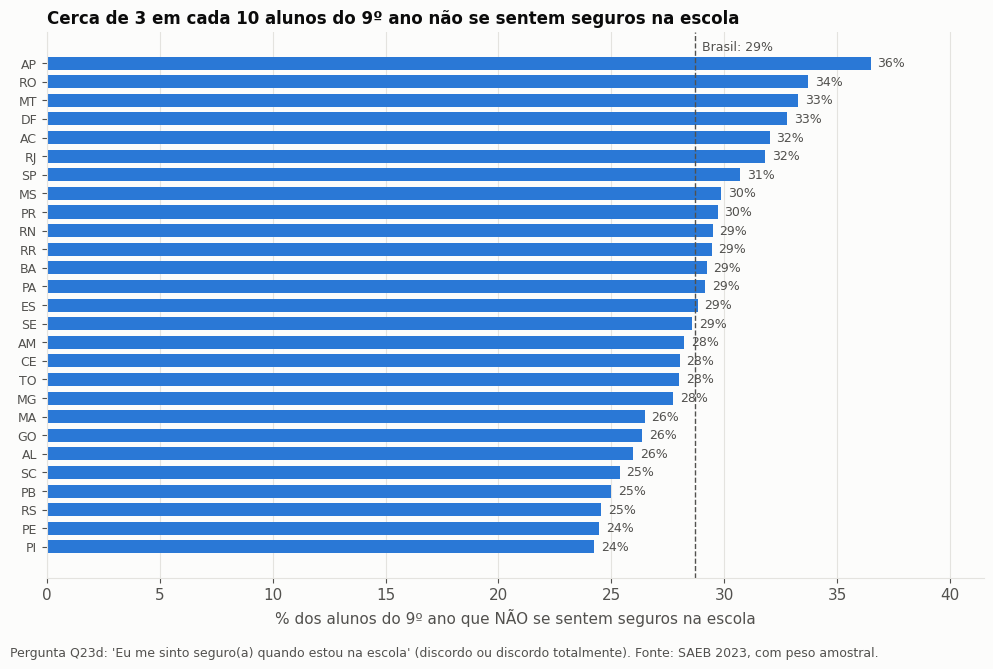

In [5]:
fig, ax = plt.subplots(figsize=(10, 6.5))
brasil = geral.loc["9º ano", "% não se sente seguro"]
y = np.arange(len(por_uf))
ax.barh(y, por_uf.values, color=AZUL, height=0.7)
for yy, v in zip(y, por_uf.values):
    ax.text(v + 0.3, yy, f"{v:.0f}%", va="center", fontsize=9, color=TEXTO2)
ax.axvline(brasil, color=TEXTO2, lw=1, ls="--")
ax.text(brasil + 0.3, len(por_uf) - 0.3, f"Brasil: {brasil:.0f}%", fontsize=9, color=TEXTO2)
ax.set_yticks(y); ax.set_yticklabels(por_uf.index, fontsize=9)
ax.set_xlim(0, por_uf.max() + 5)
ax.set_xlabel("% dos alunos do 9º ano que NÃO se sentem seguros na escola")
ax.set_title("Cerca de 3 em cada 10 alunos do 9º ano não se sentem seguros na escola")
ax.grid(True, axis="x", color=GRADE); ax.set_axisbelow(True)
fig.text(0.01, -0.02, "Pergunta Q23d: 'Eu me sinto seguro(a) quando estou na escola' (discordo ou discordo totalmente). Fonte: SAEB 2023, com peso amostral.",
         fontsize=9, color=TEXTO2)
fig.tight_layout(); fig.savefig("resultados_seguranca/fig1_inseguros_por_estado.png", dpi=150, bbox_inches="tight")

**Resultado:** no 9º ano, cerca de **3 em cada 10 alunos** não se sentem seguros na escola (2 em cada 10 no 5º ano). A diferença entre estados vai de cerca de 24% a 36%. A insegurança é maior em escolas públicas e urbanas do que em privadas e rurais.

## 2. A violência relatada pelo diretor

O questionário do diretor aparece **uma linha por série avaliada** (a mesma escola pode aparecer 2 ou 3 vezes, com as mesmas respostas). Deixamos **uma linha por escola**. Daqui em diante cada escola é uma unidade: usamos a % de alunos do 9º ano que não se sentem seguros, só nas escolas com 10 ou mais respostas.

In [6]:
dir_ = pd.read_csv("tabelas_csv/TS_DIRETOR.csv", sep=";", encoding="latin1", dtype=str)
dir_ = dir_[dir_.IN_PREENCHIMENTO_QUESTIONARIO == "1"]
print(f"linhas preenchidas: {len(dir_):,} | escolas: {dir_.ID_ESCOLA.nunique():,}")
dir_ = dir_.drop_duplicates("ID_ESCOLA")
dir_["ID_ESCOLA"] = dir_.ID_ESCOLA.astype(int)

VIOLENCIA = {"TX_Q093": "Roubo ou furto", "TX_Q094": "Tráfico de drogas", "TX_Q095": "Pessoas sob efeito de álcool",
             "TX_Q096": "Pessoas sob efeito de drogas", "TX_Q097": "Porte de arma", "TX_Q098": "Assédio sexual",
             "TX_Q099": "Discriminação", "TX_Q100": "Bullying", "TX_Q101": "Invasão da escola", "TX_Q102": "Vandalismo"}
esc = escolas9.join(dir_.set_index("ID_ESCOLA"), how="inner")
print(f"escolas do 9o ano com questionario do diretor: {len(esc):,}")

linhas = []
for col, nome in VIOLENCIA.items():
    v = esc[esc[col].isin(list("ABCD"))]
    linhas.append({"episódio": nome,
                   "% escolas onde aconteceu": v[col].isin(list("BCD")).mean() * 100,
                   "% escolas: muitas vezes/sempre": v[col].isin(["C", "D"]).mean() * 100,
                   "inseguros: nunca": v[v[col] == "A"].pct_inseguro.mean(),
                   "inseguros: poucas vezes": v[v[col] == "B"].pct_inseguro.mean(),
                   "inseguros: muitas vezes/sempre": v[v[col].isin(["C", "D"])].pct_inseguro.mean(),
                   "escolas com muitas vezes/sempre": int(v[col].isin(["C", "D"]).sum())})
violencia = pd.DataFrame(linhas).set_index("episódio").sort_values("inseguros: muitas vezes/sempre")
violencia.round(1).to_csv("resultados_seguranca/violencia_diretor.csv")
violencia.round(1)

linhas preenchidas: 89,785 | escolas: 61,870


escolas do 9o ano com questionario do diretor: 30,959


,% escolas onde aconteceu,% escolas: muitas vezes/sempre,inseguros: nunca,inseguros: poucas vezes,inseguros: muitas vezes/sempre,escolas com muitas vezes/sempre
episódio,,,,,,
Bullying,78.9,17.6,24.2,27.8,31.7,5409
Assédio sexual,11.3,0.3,27.2,32.0,32.6,83
Discriminação,47.7,4.8,26.0,29.2,32.9,1471
Pessoas sob efeito de álcool,8.4,0.2,27.3,32.4,34.4,64
Invasão da escola,9.8,1.0,27.2,32.3,35.0,318
Roubo ou furto,33.1,3.6,25.8,31.2,35.3,1101
Vandalismo,38.0,5.8,25.5,30.5,35.5,1795
Porte de arma,14.7,0.2,27.0,31.7,36.9,63
Tráfico de drogas,10.1,1.0,27.0,33.6,37.9,301


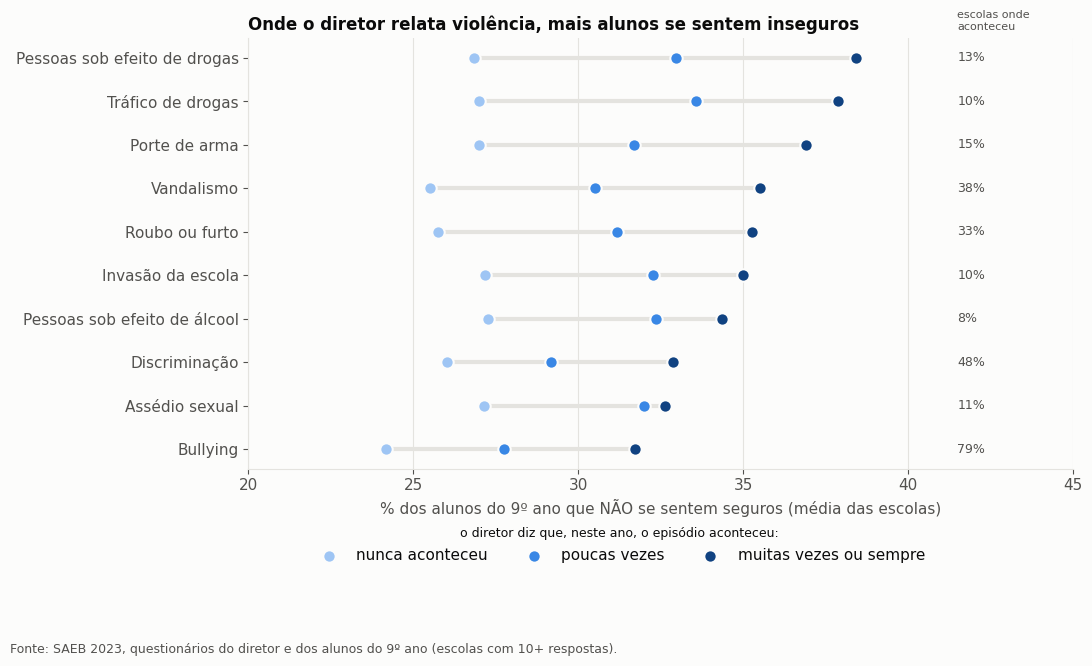

In [7]:
fig, ax = plt.subplots(figsize=(11, 6))
y = np.arange(len(violencia))
for col, cor, rotulo in [("inseguros: nunca", AZUL_1, "nunca aconteceu"), ("inseguros: poucas vezes", AZUL_2, "poucas vezes"),
                         ("inseguros: muitas vezes/sempre", AZUL_3, "muitas vezes ou sempre")]:
    ax.scatter(violencia[col], y, s=80, color=cor, label=rotulo, zorder=3, edgecolor="#fcfcfb", linewidth=1.5)
for yy, (_, l) in zip(y, violencia.iterrows()):
    ax.plot([l["inseguros: nunca"], l["inseguros: muitas vezes/sempre"]], [yy, yy], color=GRADE, lw=3, zorder=1)
    ax.text(41.5, yy, f"{l['% escolas onde aconteceu']:.0f}%", va="center", fontsize=9, color=TEXTO2)
ax.text(41.5, len(violencia) - 0.4, "escolas onde\naconteceu", fontsize=8, color=TEXTO2, va="bottom")
ax.set_yticks(y); ax.set_yticklabels(violencia.index)
ax.set_xlim(20, 45)
ax.set_xlabel("% dos alunos do 9º ano que NÃO se sentem seguros (média das escolas)")
ax.set_title("Onde o diretor relata violência, mais alunos se sentem inseguros")
ax.grid(True, axis="x", color=GRADE); ax.set_axisbelow(True)
ax.legend(frameon=False, loc="lower center", bbox_to_anchor=(0.45, -0.25), ncol=3, title="o diretor diz que, neste ano, o episódio aconteceu:", title_fontsize=9)
fig.text(0.01, -0.1, "Fonte: SAEB 2023, questionários do diretor e dos alunos do 9º ano (escolas com 10+ respostas).", fontsize=9, color=TEXTO2)
fig.tight_layout(); fig.savefig("resultados_seguranca/fig2_violencia_diretor.png", dpi=150, bbox_inches="tight")

Quanto mais **tipos** de violência o diretor relata, mais alunos se sentem inseguros? E isso continua quando comparamos escolas parecidas (mesmo estado, mesma rede e mesma localização)?

In [8]:
esc["tipos_de_violencia"] = sum(esc[col].isin(list("BCD")).astype(int) for col in VIOLENCIA)
esc["faixa"] = pd.cut(esc.tipos_de_violencia, [-1, 0, 2, 4, 10], labels=["nenhum", "1 ou 2", "3 ou 4", "5 ou mais"])
dose = esc.groupby("faixa", observed=True).agg(escolas=("pct_inseguro", "size"), pct_inseguro=("pct_inseguro", "mean"))

# comparacao entre escolas parecidas: mesmo estado, mesma rede (publica/privada) e mesma localizacao
esc["grupo_parecido"] = esc.uf.astype(str) + "_" + esc.publica.astype(str) + "_" + esc.localizacao.astype(str)
base = esc[esc.faixa == "nenhum"].groupby("grupo_parecido").pct_inseguro.mean()
dif = {"nenhum": 0.0}
for f in ["1 ou 2", "3 ou 4", "5 ou mais"]:
    g = esc[esc.faixa == f].groupby("grupo_parecido").pct_inseguro.agg(["mean", "size"]).join(base.rename("base"), how="inner")
    dif[f] = np.average(g["mean"] - g.base, weights=g["size"])
dose["diferença p/ 'nenhum' (escolas parecidas)"] = pd.Series(dif)
dose.round(1).to_csv("resultados_seguranca/tipos_de_violencia.csv")
dose.round(1)

,escolas,pct_inseguro,diferença p/ 'nenhum' (escolas parecidas)
faixa,,,
nenhum,5551,23.6,0.0
1 ou 2,11361,25.8,0.8
3 ou 4,8323,29.1,2.8
5 ou mais,5724,33.5,6.1


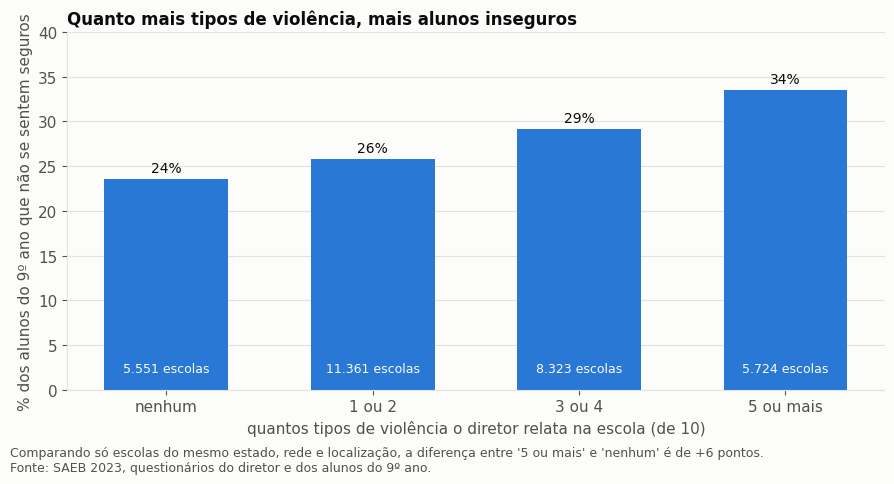

In [9]:
fig, ax = plt.subplots(figsize=(9, 4.6))
b = ax.bar(dose.index.astype(str), dose.pct_inseguro, color=AZUL, width=0.6)
ax.bar_label(b, labels=[f"{v:.0f}%" for v in dose.pct_inseguro], padding=3, fontsize=10)
for i, (f, l) in enumerate(dose.iterrows()):
    ax.text(i, 2, f"{l.escolas:,.0f} escolas".replace(",", "."), ha="center", fontsize=9, color="#fcfcfb")
ax.set_ylim(0, 40)
ax.set_xlabel("quantos tipos de violência o diretor relata na escola (de 10)")
ax.set_ylabel("% dos alunos do 9º ano que não se sentem seguros")
ax.set_title("Quanto mais tipos de violência, mais alunos inseguros")
ax.grid(True, axis="y", color=GRADE); ax.set_axisbelow(True)
fig.text(0.01, -0.04, f"Comparando só escolas do mesmo estado, rede e localização, a diferença entre '5 ou mais' e 'nenhum' é de {dose.iloc[-1, -1]:+.0f} pontos.\n"
         "Fonte: SAEB 2023, questionários do diretor e dos alunos do 9º ano.", fontsize=9, color=TEXTO2)
fig.tight_layout(); fig.savefig("resultados_seguranca/fig3_tipos_de_violencia.png", dpi=150, bbox_inches="tight")

**Resultado:** em todos os tipos de violência, a insegurança dos alunos aumenta conforme o episódio fica mais frequente. Nas escolas onde o diretor relata 5 ou mais tipos de violência, cerca de 1 em cada 3 alunos não se sente seguro, contra menos de 1 em cada 4 onde nada foi relatado. Comparando só escolas parecidas (mesmo estado, rede e localização), a diferença diminui, mas continua.

Os episódios graves são raros como "frequentes" (porte de arma, tráfico e assédio "muitas vezes" aparecem em 1% das escolas ou menos), mas **acontecer pelo menos uma vez** é comum: roubo em 1 de cada 3 escolas, discriminação em quase metade e bullying em quase 8 de cada 10.

## 3. O que os professores relatam

Os professores respondem os mesmos tipos de episódio (e mais alguns, como lesão corporal e tiroteio). Usamos só os professores do 9º ano (`ID_SERIE = 9`) e, para cada escola, a **proporção de professores** que diz que o episódio aconteceu. Comparamos escolas onde **nenhum** professor relata com escolas onde **metade ou mais** relatam.

In [10]:
prof = pd.read_csv("tabelas_csv/TS_PROFESSOR.csv", sep=";", encoding="latin1",
                   usecols=lambda c: c in ["ID_ESCOLA", "ID_SERIE"] + [f"TX_Q{i}" for i in range(135, 148)], dtype=str)
prof = prof[(prof.ID_SERIE == "9") & prof.TX_Q137.isin(list("ABCD"))].copy()
prof["ID_ESCOLA"] = prof.ID_ESCOLA.astype(int)
print(f"professores do 9o ano que responderam: {len(prof):,}")

PROF = {"TX_Q147": "Tiroteio ou bala perdida", "TX_Q135": "Atentado à vida", "TX_Q141": "Porte de arma", "TX_Q138": "Tráfico de drogas",
        "TX_Q136": "Lesão corporal", "TX_Q137": "Roubo ou furto", "TX_Q146": "Vandalismo", "TX_Q144": "Bullying"}
por_escola = prof.groupby("ID_ESCOLA").agg(**{nome: (col, lambda s: s.isin(list("BCD")).mean()) for col, nome in PROF.items()},
                                          professores=("TX_Q137", "size"))
ep = escolas9.join(por_escola, how="inner")
linhas = []
for nome in PROF.values():
    nenhum, metade = ep[ep[nome] == 0], ep[ep[nome] >= 0.5]
    linhas.append({"episódio": nome, "% escolas: algum professor relata": (ep[nome] > 0).mean() * 100,
                   "inseguros: nenhum professor relata": nenhum.pct_inseguro.mean(),
                   "inseguros: metade ou mais relatam": metade.pct_inseguro.mean(), "escolas com metade ou mais": len(metade)})
professores = pd.DataFrame(linhas).set_index("episódio")
professores.round(1).to_csv("resultados_seguranca/violencia_professores.csv")
print(f"escolas: {len(ep):,} | mediana de professores do 9o ano por escola: {ep.professores.median():.0f}")
professores.round(1)

professores do 9o ano que responderam: 128,084


escolas: 30,180 | mediana de professores do 9o ano por escola: 4


,% escolas: algum professor relata,inseguros: nenhum professor relata,inseguros: metade ou mais relatam,escolas com metade ou mais
episódio,,,,
Tiroteio ou bala perdida,4.0,27.3,33.3,770
Atentado à vida,23.9,26.5,30.7,4644
Porte de arma,21.5,26.5,31.0,4274
Tráfico de drogas,23.7,25.9,33.1,4866
Lesão corporal,60.4,24.0,30.1,15266
Roubo ou furto,57.8,23.7,30.7,14686
Vandalismo,65.3,23.4,30.0,17002
Bullying,93.0,22.5,28.0,27326


**Resultado:** a visão dos professores confirma a dos diretores. Em todos os episódios, onde metade ou mais dos professores relatam violência, a % de alunos inseguros é 4 a 7 pontos maior do que onde nenhum professor relata. As maiores diferenças aparecem em **tráfico de drogas** e **roubo** (~7 pontos). **Tiroteio ou bala perdida** é relatado por algum professor em 4% das escolas, cerca de 1.200 escolas.

## 4. O que a escola faz: estrutura e relação em sala

Comparamos a % de alunos que não se sentem seguros entre quem tem e quem não tem cada item:
- **Estrutura e ações** (resposta do diretor): projeto contra violência, trabalho com polícia/guarda, muros e grades adequados, segurança adequada na entrada e saída.
- **Relação em sala** (resposta do próprio aluno): professores falam de bullying, espaço para opiniões, à vontade para discordar, professores acreditam que ele é capaz.

Para os itens de relação em sala também comparamos alunos **da mesma escola**, para ver se não é só diferença entre escolas.

In [11]:
d9 = a9.merge(dir_[["ID_ESCOLA", "TX_Q196", "TX_Q123", "TX_Q105", "TX_Q104"]], on="ID_ESCOLA", how="left")
itens = [
    ("estrutura", "Tem projeto contra violência", d9.TX_Q196 == "B", d9.TX_Q196 == "A"),
    ("estrutura", "Trabalha com polícia ou guarda municipal", d9.TX_Q123 == "B", d9.TX_Q123 == "A"),
    ("estrutura", "Muros e grades adequados", d9.TX_Q105.isin(["C", "D"]), d9.TX_Q105.isin(["A", "B"])),
    ("estrutura", "Entrada e saída com segurança adequada", d9.TX_Q104.isin(["C", "D"]), d9.TX_Q104.isin(["A", "B"])),
    ("sala", "Professores falam de bullying e violência", d9.TX_RESP_Q22f.isin(["A", "B"]), d9.TX_RESP_Q22f.isin(["C", "D"])),
    ("sala", "Me sinto à vontade para discordar dos professores", d9.TX_RESP_Q23e.isin(["A", "B"]), d9.TX_RESP_Q23e.isin(["C", "D"])),
    ("sala", "Há espaço para opiniões diferentes na sala", d9.TX_RESP_Q23c.isin(["A", "B"]), d9.TX_RESP_Q23c.isin(["C", "D"])),
    ("sala", "Os professores acreditam que sou capaz", d9.TX_RESP_Q23h.isin(["A", "B"]), d9.TX_RESP_Q23h.isin(["C", "D"])),
]
linhas = []
for tipo, nome, sim, nao in itens:
    b = d9[sim | nao].assign(tem=sim[sim | nao].astype(int))
    linha = {"tipo": tipo, "item": nome, "% com o item": b.tem.mean() * 100,
             "inseguros: sim": b[b.tem == 1].inseguro.mean() * 100, "inseguros: não": b[b.tem == 0].inseguro.mean() * 100}
    if tipo == "sala":
        # mesma escola: diferenca entre alunos com e sem o item dentro de cada escola, media ponderada
        g = b.groupby(["ID_ESCOLA", "tem"]).inseguro.agg(["mean", "size"]).unstack().dropna()
        linha["diferença na mesma escola"] = np.average((g[("mean", 1)] - g[("mean", 0)]) * 100, weights=g[("size", 0)] + g[("size", 1)])
    linhas.append(linha)
escola_faz = pd.DataFrame(linhas).set_index("item")
escola_faz["diferença"] = escola_faz["inseguros: sim"] - escola_faz["inseguros: não"]
escola_faz.round(1).to_csv("resultados_seguranca/estrutura_e_relacao.csv")
escola_faz.round(1)

,tipo,% com o item,inseguros: sim,inseguros: não,diferença na mesma escola,diferença
item,,,,,,
Tem projeto contra violência,estrutura,95.7,30.4,29.6,NaN,0.7
Trabalha com polícia ou guarda municipal,estrutura,84.9,30.4,29.8,NaN,0.6
Muros e grades adequados,estrutura,68.4,30.1,30.9,NaN,-0.8
Entrada e saída com segurança adequada,estrutura,64.1,29.3,32.2,NaN,-2.9
Professores falam de bullying e violência,sala,58.4,26.0,36.6,-9.6,-10.6
Me sinto à vontade para discordar dos professores,sala,53.3,23.1,38.6,-15.2,-15.5
Há espaço para opiniões diferentes na sala,sala,80.7,24.5,54.8,-28.1,-30.2
Os professores acreditam que sou capaz,sala,91.8,27.4,63.3,-33.4,-35.9


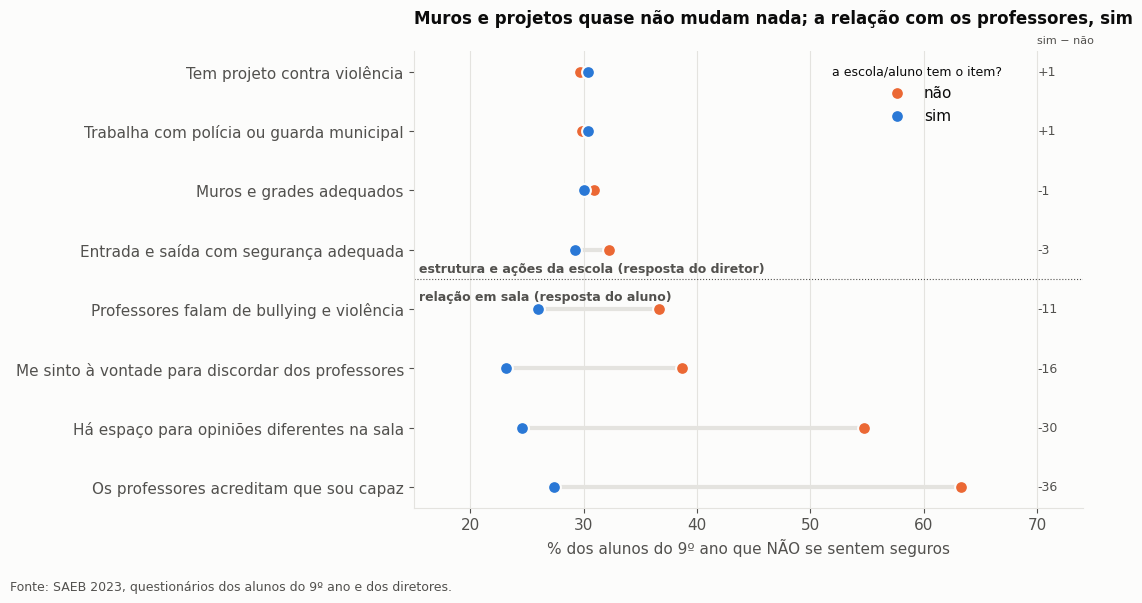

In [12]:
fig, ax = plt.subplots(figsize=(11, 5.8))
ordem = escola_faz.iloc[::-1]
y = np.arange(len(ordem))
for yy, (_, l) in zip(y, ordem.iterrows()):
    ax.plot([l["inseguros: sim"], l["inseguros: não"]], [yy, yy], color=GRADE, lw=3, zorder=1)
ax.scatter(ordem["inseguros: não"], y, s=85, color=LARANJA, label="não", zorder=3, edgecolor="#fcfcfb", linewidth=1.5)
ax.scatter(ordem["inseguros: sim"], y, s=85, color=AZUL, label="sim", zorder=3, edgecolor="#fcfcfb", linewidth=1.5)
for yy, (_, l) in zip(y, ordem.iterrows()):
    ax.text(70, yy, f"{l['diferença']:+.0f}", va="center", fontsize=9, color=TEXTO2)
ax.text(70, len(ordem) - 0.55, "sim − não", fontsize=8, color=TEXTO2, va="bottom")
ax.axhline(3.5, color=TEXTO2, lw=0.8, ls=":")
ax.text(15.5, 3.62, "estrutura e ações da escola (resposta do diretor)", fontsize=9, color=TEXTO2, fontweight="bold")
ax.text(15.5, 3.15, "relação em sala (resposta do aluno)", fontsize=9, color=TEXTO2, fontweight="bold")
ax.set_yticks(y); ax.set_yticklabels(ordem.index)
ax.set_xlim(15, 74)
ax.set_xlabel("% dos alunos do 9º ano que NÃO se sentem seguros")
ax.set_title("Muros e projetos quase não mudam nada; a relação com os professores, sim", pad=20)
ax.grid(True, axis="x", color=GRADE); ax.set_axisbelow(True)
ax.legend(frameon=False, loc="upper right", bbox_to_anchor=(0.9, 1.0), title="a escola/aluno tem o item?", title_fontsize=9)
fig.text(0.01, -0.03, "Fonte: SAEB 2023, questionários dos alunos do 9º ano e dos diretores.", fontsize=9, color=TEXTO2)
fig.tight_layout(); fig.savefig("resultados_seguranca/fig4_estrutura_e_relacao.png", dpi=150, bbox_inches="tight")

**Resultado:**
- **Estrutura e ações da escola quase não fazem diferença.** Projeto contra violência (quase todas as escolas têm), polícia/guarda e muros adequados não estão ligados a alunos mais seguros. Só a segurança na entrada e saída tem uma diferença pequena.
- **A relação em sala faz muita diferença.** Entre os alunos que acham que os professores **não** acreditam neles, a maioria não se sente segura, contra cerca de 1 em cada 4 entre os demais. O mesmo vale para ter espaço para opiniões e professores que falam de bullying.
- Essas diferenças **continuam quase iguais entre alunos da mesma escola** (coluna "diferença na mesma escola"). Então não é só que algumas escolas são melhores: dentro da mesma escola, quem tem uma relação pior com os professores se sente menos seguro.

Cuidado: "me sinto seguro" e "os professores acreditam em mim" são respostas do **mesmo aluno**. Quem está insatisfeito com a escola tende a responder mal nas duas. Por isso essa é uma associação, não prova que um causa o outro.

## Resumo para apresentar

| Pergunta | Resposta |
|---|---|
| Os alunos se sentem seguros na escola? | Cerca de **3 em cada 10** alunos do 9º ano **não** se sentem seguros (2 em cada 10 no 5º ano). Varia de ~24% a ~36% entre os estados. |
| A violência na escola está ligada a isso? | Sim. Onde diretor e professores relatam mais violência, mais alunos se sentem inseguros, mesmo comparando escolas parecidas. Drogas, tráfico e porte de arma são os episódios mais ligados. |
| Muros, polícia e projetos ajudam? | Quase não aparecem ligados a alunos mais seguros. |
| O que mais está ligado à sensação de segurança? | A **relação em sala**: professores que acreditam no aluno, espaço para opiniões e conversa sobre bullying. A diferença continua entre alunos da mesma escola. |